# Assignment 5

This assignment uses the [Fetal Health Classification dataset from Kaggle](https://www.kaggle.com/andrewmvd/fetal-health-classification).

## Context (from Kaggle)

The reduction of child mortality is reflected in several of the United Nations’ Sustainable Development Goals and is a key indicator of human progress. The UN expects that by 2030, countries end preventable deaths of newborns and children under five years of age, with all countries aiming to reduce under-5 mortality to at least as low as 25 per 1,000 live births.

Parallel to child mortality is maternal mortality, accounting for 295,000 deaths during and following pregnancy and childbirth (as of 2017). Most of these deaths (94%) occurred in low-resource settings, and most could have been prevented.

Cardiotocogram (CTG) is a cost-accessible option to assess fetal health, allowing healthcare professionals to take action to prevent child and maternal mortality. The equipment works by sending ultrasound pulses and reading its response, thus highlighting fetal heart rate (FHR), fetal movements, uterine contractions, and more.

## Data (from Kaggle)

This dataset contains 2,126 records of features extracted from Cardiotocogram exams, which were then classified by three expert obstetricians into three classes:

- Normal
- Suspect
- Pathological

In this assignment, you will build a multiclass classification model to classify fetal health states (normal, suspect, and pathological) based on all CTG features available in the dataset.

In [1]:
import kagglehub
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pandas.plotting import scatter_matrix
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import SGDClassifier
from sklearn.model_selection import cross_val_score
from sklearn.dummy import DummyClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

## Question 1

Read the data into Google Colab using the `.read_csv()` function.

In [2]:
path = kagglehub.dataset_download("andrewmvd/fetal-health-classification")
print("Path to dataset files:", path)
os.listdir(path)

Using Colab cache for faster access to the 'fetal-health-classification' dataset.
Path to dataset files: /kaggle/input/fetal-health-classification


['fetal_health.csv']

In [3]:
file_name = "fetal_health.csv"
df = pd.read_csv(os.path.join(path, file_name))

## Question 2

Print the first and last five rows of the dataframe using `.head()` and `.tail()` functions. How many observations (i.e., sample size) do you have in total?

In [4]:
print(df.head(5))
print()
print(df.tail(5))
print()
print("Number of observations:", len(df))

   baseline value  accelerations  fetal_movement  uterine_contractions  \
0           120.0          0.000             0.0                 0.000   
1           132.0          0.006             0.0                 0.006   
2           133.0          0.003             0.0                 0.008   
3           134.0          0.003             0.0                 0.008   
4           132.0          0.007             0.0                 0.008   

   light_decelerations  severe_decelerations  prolongued_decelerations  \
0                0.000                   0.0                       0.0   
1                0.003                   0.0                       0.0   
2                0.003                   0.0                       0.0   
3                0.003                   0.0                       0.0   
4                0.000                   0.0                       0.0   

   abnormal_short_term_variability  mean_value_of_short_term_variability  \
0                             73.0

## Question 3

Use `.info()` to get a short description of the dataframe.

In [5]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2126 entries, 0 to 2125
Data columns (total 22 columns):
 #   Column                                                  Non-Null Count  Dtype  
---  ------                                                  --------------  -----  
 0   baseline value                                          2126 non-null   float64
 1   accelerations                                           2126 non-null   float64
 2   fetal_movement                                          2126 non-null   float64
 3   uterine_contractions                                    2126 non-null   float64
 4   light_decelerations                                     2126 non-null   float64
 5   severe_decelerations                                    2126 non-null   float64
 6   prolongued_decelerations                                2126 non-null   float64
 7   abnormal_short_term_variability                         2126 non-null   float64
 8   mean_value_of_short_term_variability  

## Question 4

Take a look at the target (i.e., `fetal_health`) using the `.value_counts()` function. What is the prevalence of each fetal health status in the dataframe?

In [6]:
df.value_counts("fetal_health")

,count
fetal_health,
1.0,1655
2.0,295
3.0,176


Prevalence of each fetal health category: 1655 Normal, 295 Suspect, and 176 Pathological.

## Question 5

Report the descriptive statistics of the numerical features using the `.describe()` function.

In [7]:
df.describe()

,baseline value,accelerations,fetal_movement,uterine_contractions,light_decelerations,severe_decelerations,prolongued_decelerations,abnormal_short_term_variability,mean_value_of_short_term_variability,percentage_of_time_with_abnormal_long_term_variability,...,histogram_min,histogram_max,histogram_number_of_peaks,histogram_number_of_zeroes,histogram_mode,histogram_mean,histogram_median,histogram_variance,histogram_tendency,fetal_health
count,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.00000,...,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000
mean,133.303857,0.003178,0.009481,0.004366,0.001889,0.000003,0.000159,46.990122,1.332785,9.84666,...,93.579492,164.025400,4.068203,0.323612,137.452023,134.610536,138.090310,18.808090,0.320320,1.304327
std,9.840844,0.003866,0.046666,0.002946,0.002960,0.000057,0.000590,17.192814,0.883241,18.39688,...,29.560212,17.944183,2.949386,0.706059,16.381289,15.593596,14.466589,28.977636,0.610829,0.614377
min,106.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,12.000000,0.200000,0.00000,...,50.000000,122.000000,0.000000,0.000000,60.000000,73.000000,77.000000,0.000000,-1.000000,1.000000
25%,126.000000,0.000000,0.000000,0.002000,0.000000,0.000000,0.000000,32.000000,0.700000,0.00000,...,67.000000,152.000000,2.000000,0.000000,129.000000,125.000000,129.000000,2.000000,0.000000,1.000000
50%,133.000000,0.002000,0.000000,0.004000,0.000000,0.000000,0.000000,49.000000,1.200000,0.00000,...,93.000000,162.000000,3.000000,0.000000,139.000000,136.000000,139.000000,7.000000,0.000000,1.000000
75%,140.000000,0.006000,0.003000,0.007000,0.003000,0.000000,0.000000,61.000000,1.700000,11.00000,...,120.000000,174.000000,6.000000,0.000000,148.000000,145.000000,148.000000,24.000000,1.000000,1.000000
max,160.000000,0.019000,0.481000,0.015000,0.015000,0.001000,0.005000,87.000000,7.000000,91.00000,...,159.000000,238.000000,18.000000,10.000000,187.000000,182.000000,186.000000,269.000000,1.000000,3.000000


## Question 6

Choose five numerical features of your interest and plot histograms for each feature.

array([[<Axes: title={'center': 'baseline value'}>,
        <Axes: title={'center': 'accelerations'}>],
       [<Axes: title={'center': 'uterine_contractions'}>,
        <Axes: title={'center': 'light_decelerations'}>],
       [<Axes: title={'center': 'abnormal_short_term_variability'}>,
        <Axes: >]], dtype=object)

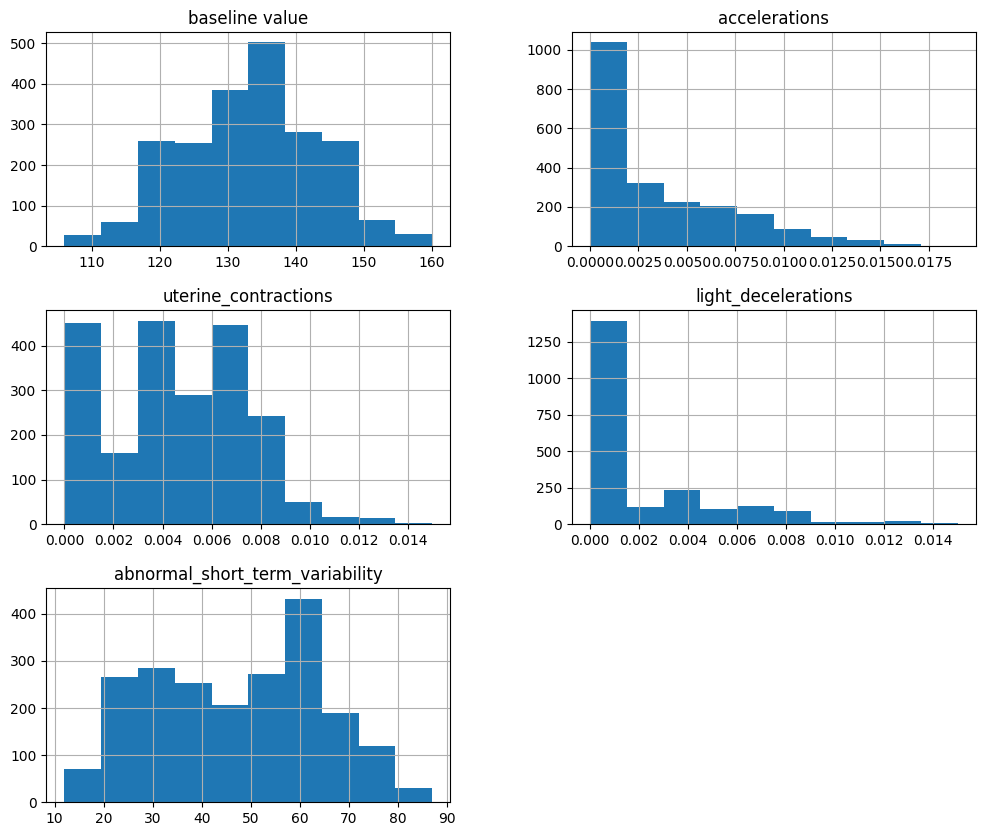

In [8]:
features = [
    "baseline value",
    "accelerations",
    "uterine_contractions",
    "light_decelerations",
    "abnormal_short_term_variability"
]

df[features].hist(figsize= (12,10))

## Question 7

Plot a scatter matrix of the features in Question 6 and the target. Pay special attention to the bivariate relationship between each of the features and the target. What relationships can you tell, if any, between any features and the target? Describe the direction of a relationship as positive or negative.

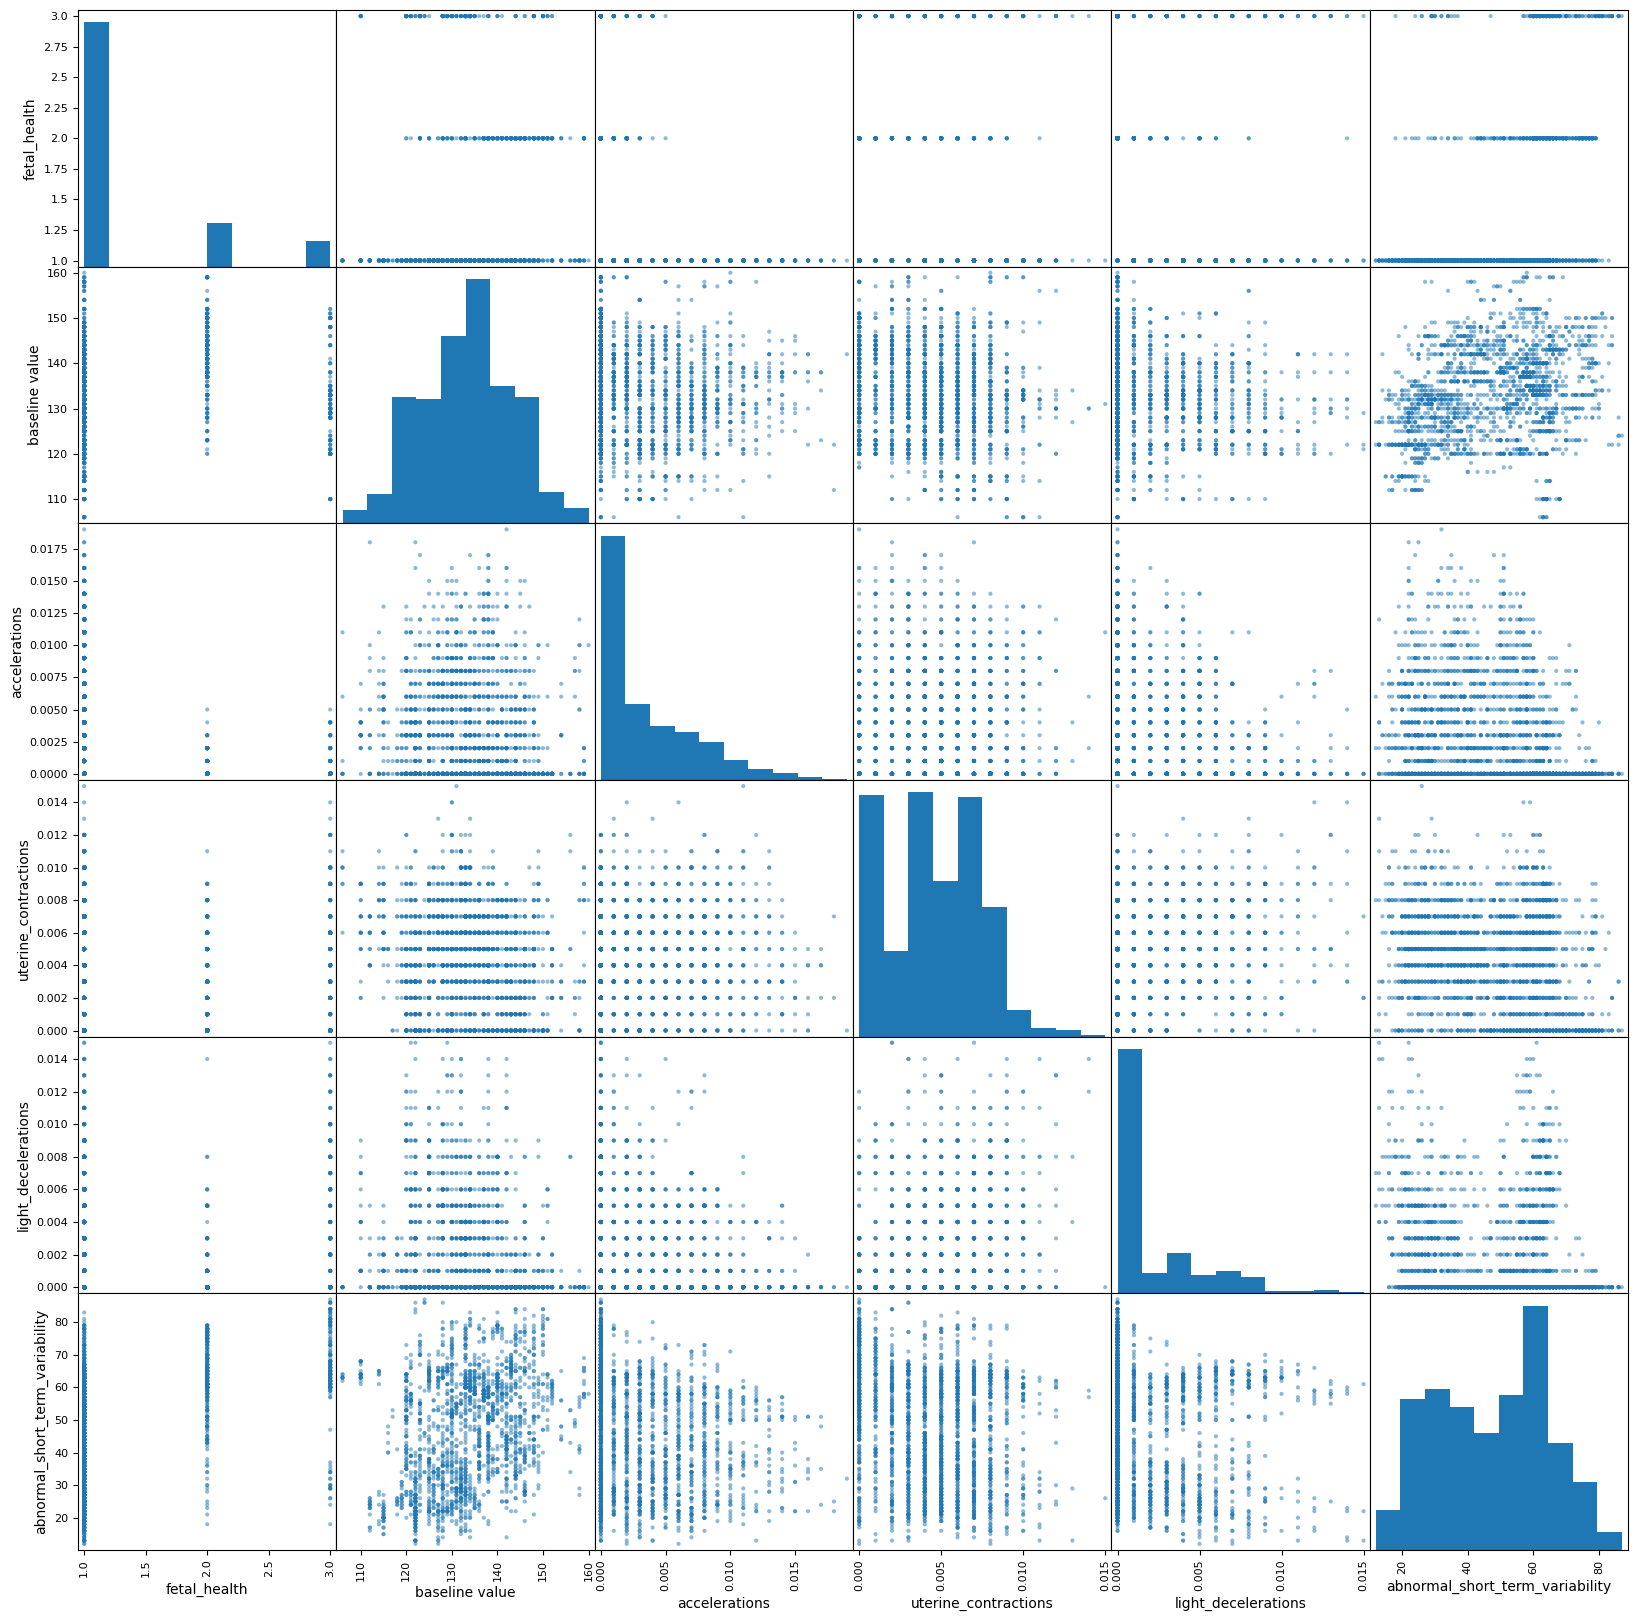

In [9]:
attributes = ["fetal_health"] + features

scatter_matrix(
    df[attributes],
    figsize=(20, 20),
    alpha=0.5
)

plt.show()

Abnormal short-term variability shows the cleareast pattern with fetal-health severity, with a positive relationship where the higher abnormal short-term variability is correlated with a higher fetal-health severity. Accelerations have a negative relationship. Uterine contractions and light decelerations show weak negative relationships, while baseline value has no clear relationship as there's substantial overlap among the three classes.

## Question 8

Create a pipeline to process numeric features (all features are numeric in the dataframe) using the `.Pipeline()` function. In the pipeline, include the following two processes: first, replace missing values of a feature with its median; and second, standardize the feature.

In [10]:
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("std_scaler", StandardScaler())
])

## Question 9

Use the `.train_test_split()` function to split the dataframe into a train set and a test set, in which the test set occupies 20% of the data.

*Hint: You might need to create two NumPy arrays, one for the features and the other for the target, before applying `.train_test_split()`.*

In [11]:
y = df["fetal_health"]
X = df.drop("fetal_health", axis=1)

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

# Place 20% of observations in the test set
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

Feature shape: (2126, 21)
Target shape: (2126,)


## Question 10

Fit and transform the train set using the pipeline.

In [12]:
X_train_prepared = num_pipeline.fit_transform(X_train)

## Question 11

Transform the test set using the pipeline.

In [13]:
X_test_prepared = num_pipeline.transform(X_test)

## Question 12

Fit a stochastic gradient descent (SGD) classifier on the train set.

In [14]:
sgd_clf = SGDClassifier()
sgd_clf.fit(X_train_prepared, y_train)

SGDClassifier()

## Question 13

Measure the accuracy using 5-fold cross-validation on the train set.

In [15]:
scores = cross_val_score(
    sgd_clf,
    X_train_prepared,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("Fold accuracies:", scores)
print("Mean accuracy:", scores.mean())

Fold accuracies: [0.91764706 0.84705882 0.90882353 0.88235294 0.89117647]
Mean accuracy: 0.8894117647058823


## Question 14

Use the `.DummyClassifier()` function to obtain the baseline accuracy (i.e., “raw” accuracy based on the simple majority rule without modeling). See the [scikit-learn DummyClassifier documentation](https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html). Compare the baseline accuracy to the model accuracy reported in Question 13. Does your model perform better than the baseline?

In [16]:
dummy_clf = DummyClassifier(strategy="most_frequent")
dummy_clf.fit(X_train_prepared, y_train)
dummy_accuracy = dummy_clf.score(X_train_prepared, y_train)

print("Baseline accuracy:", dummy_accuracy)

Baseline accuracy: 0.7776470588235294


Compared to the 77.8% accuracy of the baseline dummy classifier, SGD classifier has an accuracy of 88.1%, which is 10 percentage points better.

## Question 15

Construct a confusion matrix based on the predictions made by the SGD classifier on the test set.

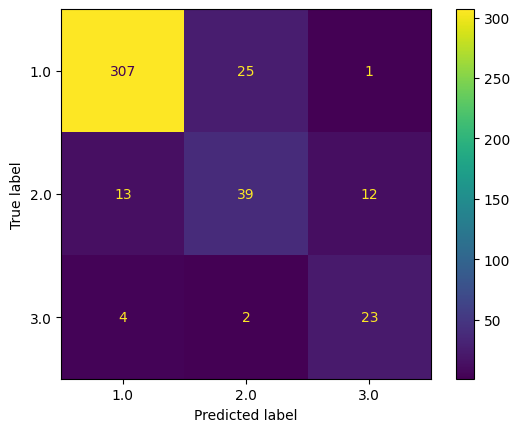

In [17]:
ConfusionMatrixDisplay.from_estimator(sgd_clf, X_test_prepared, y_test)

## Question 16

Calculate and print precision, recall, and F-1 score based on the predictions made by the SGD classifier on the test set.

In [20]:
y_test_pred = sgd_clf.predict(X_test_prepared)

print("Precision: ", precision_score(y_test, y_test_pred, average="weighted") )# precision = TP / (TP + FP)
print('\n')
print("Recall: ", recall_score(y_test, y_test_pred, average="weighted")) # recall = TP / (TP + FN)
print('\n')
print("F1 score: ", f1_score(y_test, y_test_pred, average="weighted")) # f1 score = 2 * precision * recall / (precision + recall)

Precision:  0.8729430454782567


Recall:  0.8661971830985915


F1 score:  0.8688463764674452


## Question 17

Train a random-forest classifier and compare modeling results (i.e., accuracy, precision, recall, and F-1 score on the test set) with those obtained from the SGD classifier.

In [21]:
forest_clf = RandomForestClassifier(random_state=42)
forest_clf.fit(X_train_prepared, y_train)

y_test_pred_forest = forest_clf.predict(X_test_prepared)

In [22]:
results = pd.DataFrame({
    "SGD": [
        accuracy_score(y_test, y_test_pred),
        precision_score(y_test, y_test_pred, average="weighted"),
        recall_score(y_test, y_test_pred, average="weighted"),
        f1_score(y_test, y_test_pred, average="weighted")
    ],
    "Random Forest": [
        accuracy_score(y_test, y_test_pred_forest),
        precision_score(y_test, y_test_pred_forest, average="weighted"),
        recall_score(y_test, y_test_pred_forest, average="weighted"),
        f1_score(y_test, y_test_pred_forest, average="weighted")
    ]
}, index=["Accuracy", "Precision", "Recall", "F1 score"])

results

,SGD,Random Forest
Accuracy,0.866197,0.948357
Precision,0.872943,0.947210
Recall,0.866197,0.948357
F1 score,0.868846,0.946715


The author acknowledge the use of GPT-5.6 Sol Light, developed by OpenAI, in preparing this assignment. The tool was used to generate the ipynb file shell from the word doc and debugging some of the problems.